<a href="https://colab.research.google.com/github/Chaki34/SaiKet_Systems_Data_Science_Internship/blob/main/SaiKet_Systems_Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Task 3: Customer Segmentation

## Project: Customer Churn Analysis and Prediction

**Organization:** SaiKet Systems  
**Internship Domain:** Data Science  
**Task:** Customer Segmentation

### Objective

The objective of this task is to segment customers based on tenure, monthly charges, and contract type.

The analysis focuses on understanding customer behavior, calculating churn rates within different customer segments, identifying high-value customers, and identifying high-value customers who may require special attention to improve customer retention.

### Dataset
Telco Customer Churn Dataset

### Technologies Used
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Key Activities
1. Customer Segmentation by Tenure
2. Customer Segmentation by Monthly Charges
3. Customer Segmentation by Contract Type
4. Churn Rate Analysis Across Segments
5. High-Value Customer Identification
6. Identification of High-Value Customers at Risk


In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

import os
import warnings

warnings.filterwarnings('ignore')

# Pandas display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style='whitegrid', palette='Set2')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Load Dataset

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

print("\nDataset Shape:", df.shape)

display(df.head())


Saving Telco_Customer_Churn_Dataset  (3) (1).csv to Telco_Customer_Churn_Dataset  (3) (1).csv
Dataset loaded successfully!

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

# Step 3: Inspect Dataset

print("Dataset Information:")
df.info()

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include='all').T)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

# Step 4: Data Cleaning and Preprocessing

df = df.copy()

# Remove unnecessary spaces
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Convert numerical columns
df['tenure'] = pd.to_numeric(
    df['tenure'],
    errors='coerce'
)

df['MonthlyCharges'] = pd.to_numeric(
    df['MonthlyCharges'],
    errors='coerce'
)

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Remove records missing essential segmentation values
required_columns = [
    'tenure',
    'MonthlyCharges',
    'Contract',
    'Churn'
]

df.dropna(subset=required_columns, inplace=True)

# Keep valid churn categories
df = df[df['Churn'].isin(['Yes', 'No'])]

# Validate numerical values
df = df[
    (df['tenure'] >= 0) &
    (df['MonthlyCharges'] >= 0)
].copy()

print("Data preprocessing completed!")

print("\nCleaned Dataset Shape:", df.shape)

display(df[required_columns].head())


Data preprocessing completed!

Cleaned Dataset Shape: (7043, 21)


,tenure,MonthlyCharges,Contract,Churn
0,1,29.85,Month-to-month,No
1,34,56.95,One year,No
2,2,53.85,Month-to-month,Yes
3,45,42.30,One year,No
4,2,70.70,Month-to-month,Yes


In [5]:

# Step 5: Create Customer Segments Based on Tenure

tenure_bins = [-1, 12, 24, 48, 72]

tenure_labels = [
    'New Customers',
    'Developing Customers',
    'Established Customers',
    'Loyal Customers'
]

df['TenureSegment'] = pd.cut(
    df['tenure'],
    bins=tenure_bins,
    labels=tenure_labels
)

print("Tenure Segmentation Completed!")

print("\nCustomer Distribution by Tenure Segment:")

tenure_distribution = df['TenureSegment'].value_counts(
    sort=False
)

display(
    tenure_distribution.to_frame(
        name='Customer Count'
    )
)


Tenure Segmentation Completed!

Customer Distribution by Tenure Segment:


,Customer Count
TenureSegment,
New Customers,2186
Developing Customers,1024
Established Customers,1594
Loyal Customers,2239


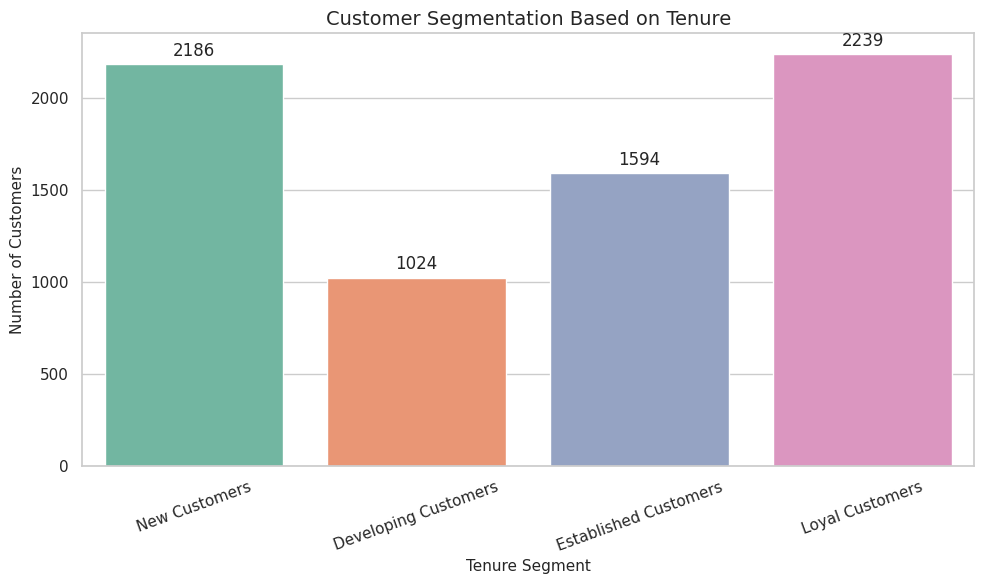

In [6]:

# Step 6: Visualize Tenure Segments

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x='TenureSegment',
    hue='TenureSegment',
    order=tenure_labels,
    legend=False
)

plt.title('Customer Segmentation Based on Tenure')
plt.xlabel('Tenure Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


In [7]:

# Step 7: Create Customer Segments Based on Monthly Charges

low_threshold = df['MonthlyCharges'].quantile(0.33)
high_threshold = df['MonthlyCharges'].quantile(0.66)

df['MonthlyChargeSegment'] = np.select(
    [
        df['MonthlyCharges'] <= low_threshold,
        df['MonthlyCharges'] <= high_threshold
    ],
    [
        'Low-Spending Customers',
        'Medium-Spending Customers'
    ],
    default='High-Spending Customers'
)

print("Monthly Charge Segmentation Completed!")

print(f"\nLow Spending Threshold: ${low_threshold:.2f}")
print(f"High Spending Threshold: ${high_threshold:.2f}")

monthly_distribution = df[
    'MonthlyChargeSegment'
].value_counts()

print("\nCustomer Distribution by Monthly Charges:")

display(
    monthly_distribution.to_frame(
        name='Customer Count'
    )
)


Monthly Charge Segmentation Completed!

Low Spending Threshold: $50.20
High Spending Threshold: $83.20

Customer Distribution by Monthly Charges:


,Customer Count
MonthlyChargeSegment,
High-Spending Customers,2392
Low-Spending Customers,2327
Medium-Spending Customers,2324


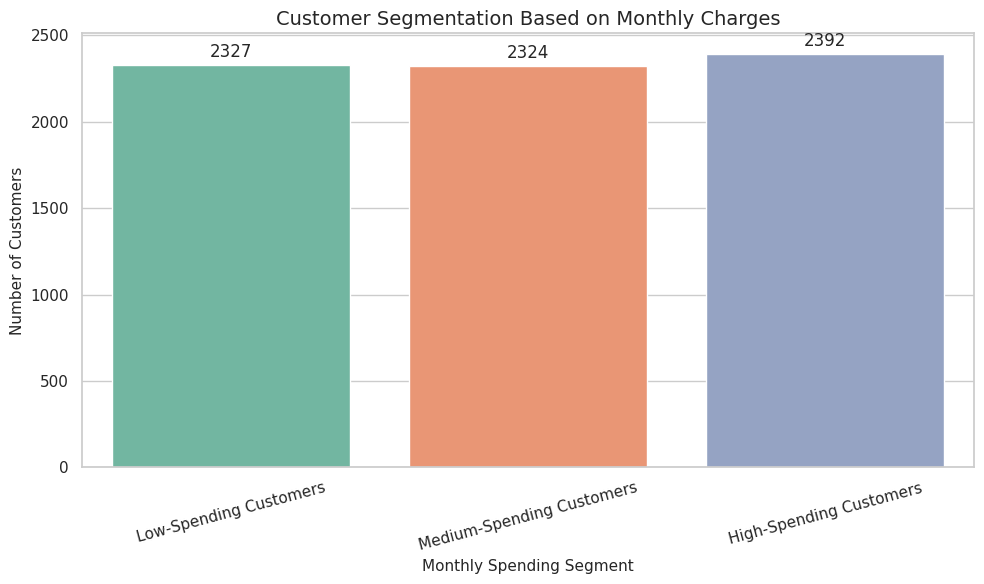

In [8]:

# Step 8: Visualize Monthly Charge Segments

charge_order = [
    'Low-Spending Customers',
    'Medium-Spending Customers',
    'High-Spending Customers'
]

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x='MonthlyChargeSegment',
    hue='MonthlyChargeSegment',
    order=charge_order,
    legend=False
)

plt.title('Customer Segmentation Based on Monthly Charges')
plt.xlabel('Monthly Spending Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


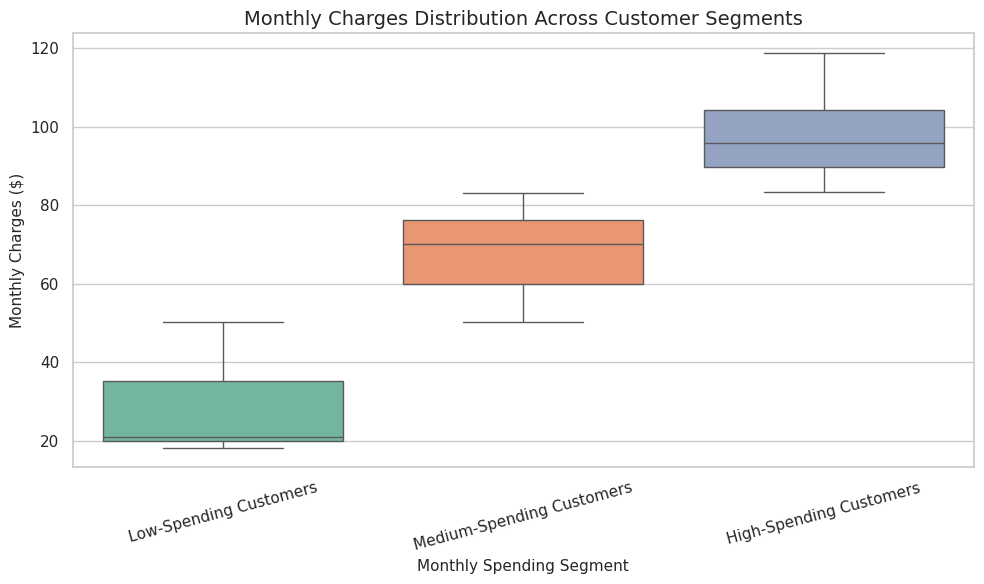

In [9]:

# Step 9: Monthly Charges Distribution by Segment

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='MonthlyChargeSegment',
    y='MonthlyCharges',
    hue='MonthlyChargeSegment',
    order=charge_order,
    legend=False
)

plt.title('Monthly Charges Distribution Across Customer Segments')
plt.xlabel('Monthly Spending Segment')
plt.ylabel('Monthly Charges ($)')

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [10]:

# Step 10: Segment Customers Based on Contract Type

contract_distribution = df['Contract'].value_counts()

print("Customer Distribution by Contract Type:")

display(
    contract_distribution.to_frame(
        name='Customer Count'
    )
)

print("\nUnique Contract Types:")
print(df['Contract'].unique())


Customer Distribution by Contract Type:


,Customer Count
Contract,
Month-to-month,3875
Two year,1695
One year,1473



Unique Contract Types:
['Month-to-month' 'One year' 'Two year']


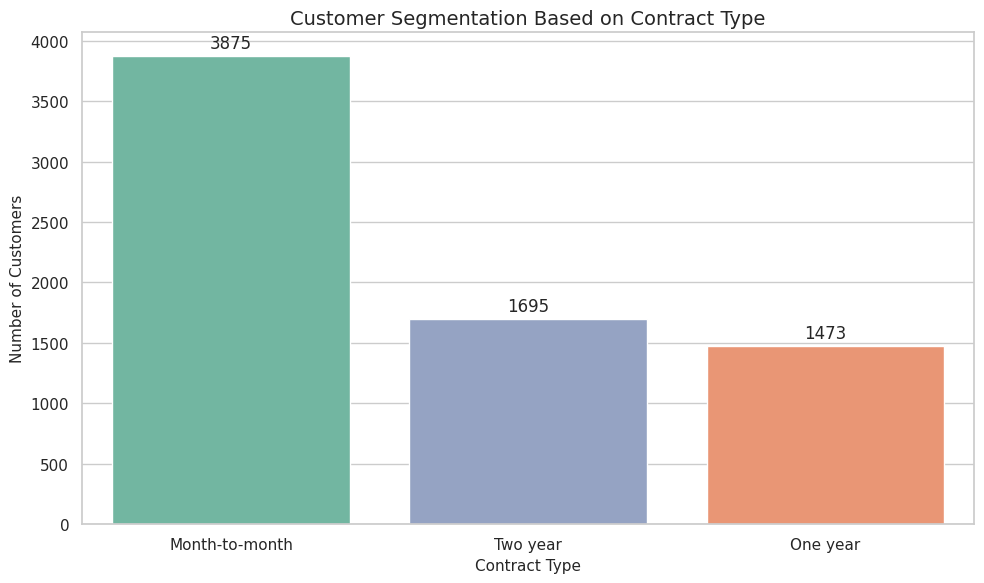

In [11]:

# Step 11: Visualize Contract Type Segmentation

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x='Contract',
    hue='Contract',
    legend=False,
    order=contract_distribution.index
)

plt.title('Customer Segmentation Based on Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


In [12]:

# Step 12: Churn Analysis by Tenure Segment

tenure_churn = df.groupby(
    'TenureSegment',
    observed=False
).agg(
    Total_Customers=('Churn', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    )
)

tenure_churn['Churn_Rate'] = (
    tenure_churn['Churned_Customers'] /
    tenure_churn['Total_Customers']
) * 100

print("Churn Analysis by Tenure Segment:")

display(tenure_churn.round(2))


Churn Analysis by Tenure Segment:


,Total_Customers,Churned_Customers,Churn_Rate
TenureSegment,,,
New Customers,2186,1037,47.44
Developing Customers,1024,294,28.71
Established Customers,1594,325,20.39
Loyal Customers,2239,213,9.51


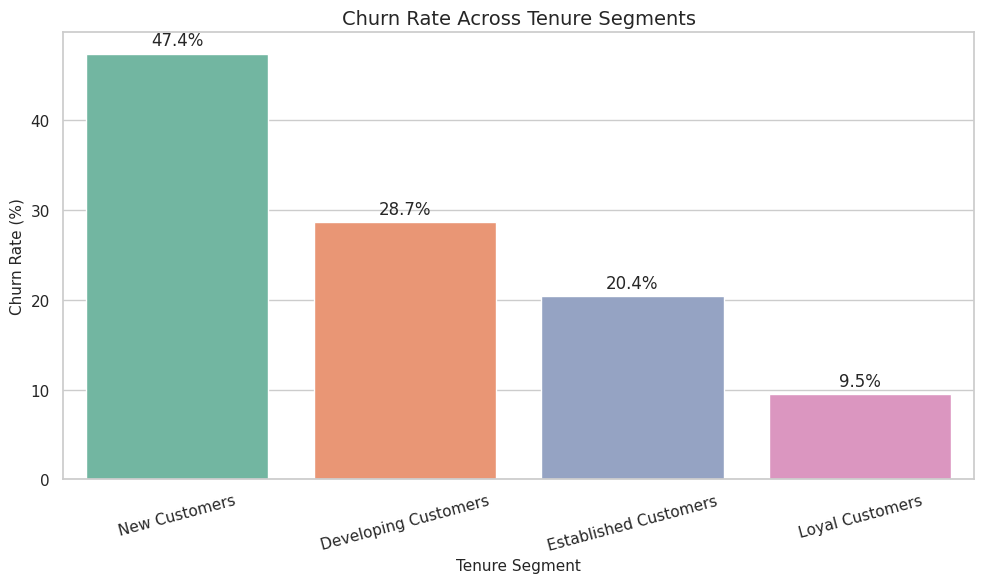

In [13]:

# Step 13: Visualize Tenure-wise Churn Rate

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=tenure_churn.reset_index(),
    x='TenureSegment',
    y='Churn_Rate',
    hue='TenureSegment',
    order=tenure_labels,
    legend=False
)

plt.title('Churn Rate Across Tenure Segments')
plt.xlabel('Tenure Segment')
plt.ylabel('Churn Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [14]:

# Step 14: Churn Analysis by Monthly Charge Segment

monthly_churn = df.groupby(
    'MonthlyChargeSegment',
    observed=False
).agg(
    Total_Customers=('Churn', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    ),
    Average_Monthly_Charges=(
        'MonthlyCharges',
        'mean'
    )
)

monthly_churn['Churn_Rate'] = (
    monthly_churn['Churned_Customers'] /
    monthly_churn['Total_Customers']
) * 100

monthly_churn = monthly_churn.reindex(charge_order)

print("Churn Analysis by Monthly Spending Segment:")

display(monthly_churn.round(2))


Churn Analysis by Monthly Spending Segment:


,Total_Customers,Churned_Customers,Average_Monthly_Charges,Churn_Rate
MonthlyChargeSegment,,,,
Low-Spending Customers,2327,367,27.76,15.77
Medium-Spending Customers,2324,684,68.56,29.43
High-Spending Customers,2392,818,97.07,34.20


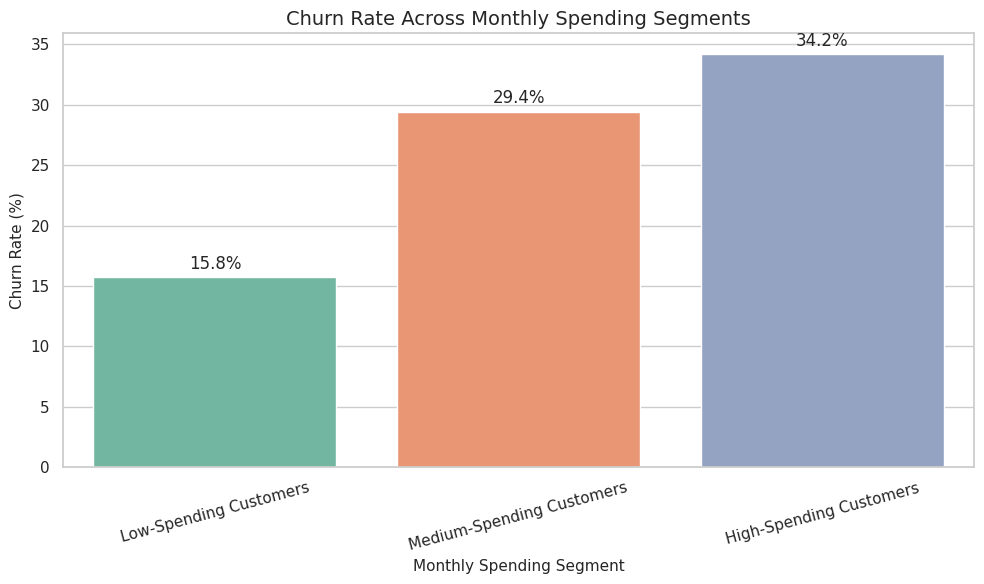

In [15]:

# Step 15: Visualize Monthly Spending-wise Churn Rate

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=monthly_churn.reset_index(),
    x='MonthlyChargeSegment',
    y='Churn_Rate',
    hue='MonthlyChargeSegment',
    order=charge_order,
    legend=False
)

plt.title('Churn Rate Across Monthly Spending Segments')
plt.xlabel('Monthly Spending Segment')
plt.ylabel('Churn Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [16]:

# Step 16: Churn Analysis by Contract Type

contract_churn = df.groupby(
    'Contract'
).agg(
    Total_Customers=('Churn', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    )
)

contract_churn['Churn_Rate'] = (
    contract_churn['Churned_Customers'] /
    contract_churn['Total_Customers']
) * 100

print("Churn Analysis by Contract Type:")

display(contract_churn.round(2))


Churn Analysis by Contract Type:


,Total_Customers,Churned_Customers,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


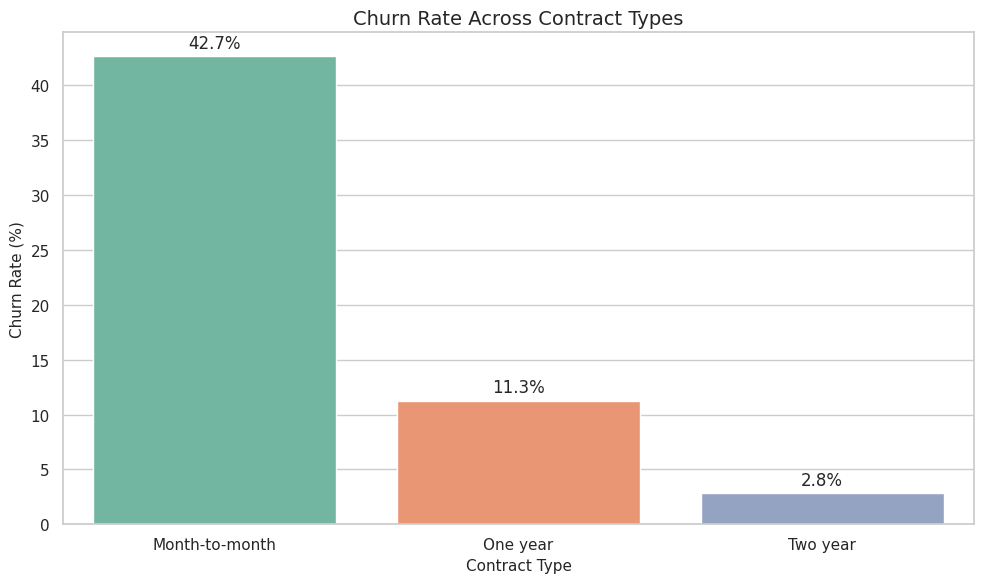

In [17]:

# Step 17: Visualize Contract-wise Churn Rate

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=contract_churn.reset_index(),
    x='Contract',
    y='Churn_Rate',
    hue='Contract',
    legend=False
)

plt.title('Churn Rate Across Contract Types')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.show()


In [18]:

# Step 18: Combined Customer Segmentation

combined_segmentation = df.groupby(
    [
        'TenureSegment',
        'MonthlyChargeSegment',
        'Contract'
    ],
    observed=False
).agg(
    Total_Customers=('Churn', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    ),
    Average_Monthly_Charges=(
        'MonthlyCharges',
        'mean'
    )
).reset_index()

combined_segmentation['Churn_Rate'] = (
    combined_segmentation['Churned_Customers'] /
    combined_segmentation['Total_Customers'].replace(0, np.nan)
) * 100

combined_segmentation = combined_segmentation.dropna(
    subset=['Churn_Rate']
)

print("Combined Customer Segmentation Analysis:")

display(
    combined_segmentation.sort_values(
        'Churn_Rate',
        ascending=False
    ).head(20).round(2)
)


Combined Customer Segmentation Analysis:


,TenureSegment,MonthlyChargeSegment,Contract,Total_Customers,Churned_Customers,Average_Monthly_Charges,Churn_Rate
0,New Customers,High-Spending Customers,Month-to-month,382,285.0,92.07,74.61
6,New Customers,Medium-Spending Customers,Month-to-month,822,456.0,69.25,55.47
9,Developing Customers,High-Spending Customers,Month-to-month,279,150.0,93.43,53.76
18,Established Customers,High-Spending Customers,Month-to-month,406,178.0,95.47,43.84
3,New Customers,Low-Spending Customers,Month-to-month,790,283.0,30.37,35.82
15,Developing Customers,Medium-Spending Customers,Month-to-month,283,94.0,69.01,33.22
27,Loyal Customers,High-Spending Customers,Month-to-month,231,70.0,97.71,30.30
1,New Customers,High-Spending Customers,One year,7,2.0,95.04,28.57
24,Established Customers,Medium-Spending Customers,Month-to-month,257,68.0,68.46,26.46
10,Developing Customers,High-Spending Customers,One year,18,4.0,95.72,22.22


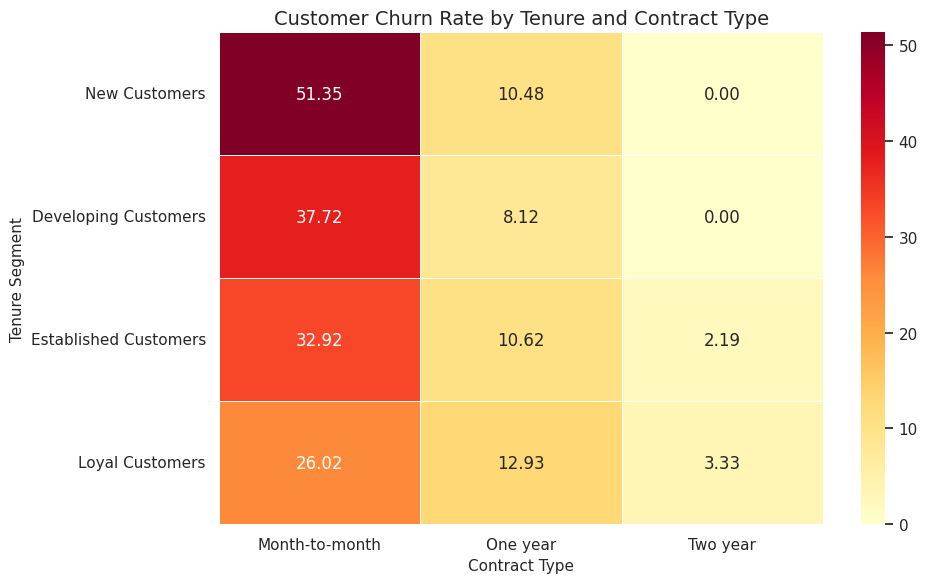

In [19]:

# Step 19: Heatmap of Churn Rate by Tenure and Contract

heatmap_data = df.pivot_table(
    index='TenureSegment',
    columns='Contract',
    values='Churn',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=False
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Customer Churn Rate by Tenure and Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Tenure Segment')

plt.tight_layout()
plt.show()


In [20]:

# Step 20: Identify High-Value Customers

high_value_threshold = df['MonthlyCharges'].quantile(0.75)

df['CustomerValueSegment'] = np.where(
    df['MonthlyCharges'] >= high_value_threshold,
    'High-Value Customer',
    'Regular-Value Customer'
)

print(
    f"High-Value Customer Threshold: "
    f"${high_value_threshold:.2f}"
)

print("\nCustomer Value Distribution:")

value_distribution = df[
    'CustomerValueSegment'
].value_counts()

display(
    value_distribution.to_frame(
        name='Customer Count'
    )
)


High-Value Customer Threshold: $89.85

Customer Value Distribution:


,Customer Count
CustomerValueSegment,
Regular-Value Customer,5272
High-Value Customer,1771


In [21]:

# Step 21: High-Value Customer Analysis

high_value_customers = df[
    df['CustomerValueSegment'] == 'High-Value Customer'
].copy()

high_value_analysis = high_value_customers.groupby(
    'Churn'
).agg(
    Customer_Count=('customerID', 'count'),
    Average_Tenure=('tenure', 'mean'),
    Average_Monthly_Charges=('MonthlyCharges', 'mean'),
    Average_Total_Charges=('TotalCharges', 'mean')
)

print("High-Value Customer Analysis:")

display(high_value_analysis.round(2))

print(
    "\nTotal High-Value Customers:",
    len(high_value_customers)
)


High-Value Customer Analysis:


,Customer_Count,Average_Tenure,Average_Monthly_Charges,Average_Total_Charges
Churn,,,,
No,1191,51.68,101.48,5304.05
Yes,580,30.45,99.45,3092.89



Total High-Value Customers: 1771


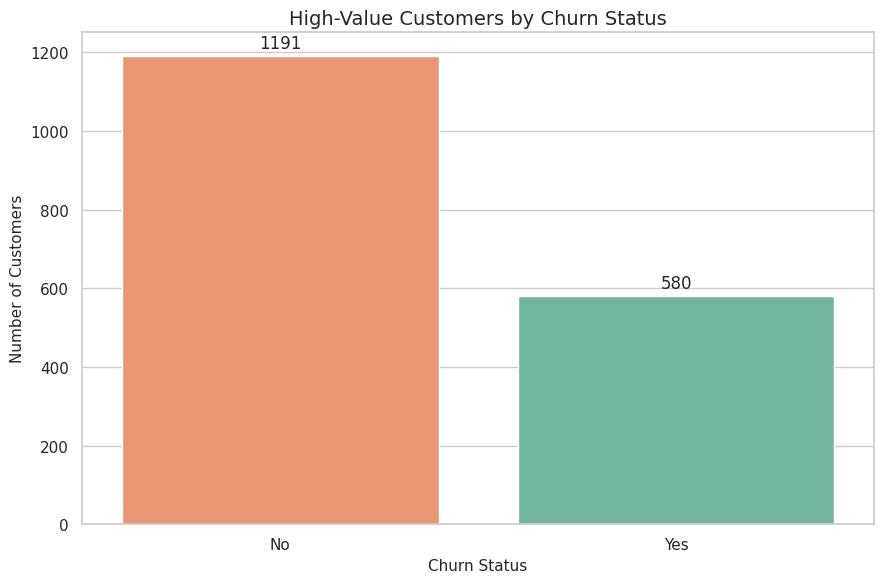

In [22]:

# Step 22: Visualize High-Value Customers by Churn Status

plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=high_value_customers,
    x='Churn',
    hue='Churn',
    order=['No', 'Yes'],
    legend=False
)

plt.title('High-Value Customers by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


In [23]:

# Step 23: Calculate Overall Churn Rate

overall_churn_rate = (
    (df['Churn'] == 'Yes').mean() * 100
)

print(
    f"Overall Customer Churn Rate: "
    f"{overall_churn_rate:.2f}%"
)


Overall Customer Churn Rate: 26.54%


In [24]:

# Step 24: Identify High-Risk Customer Segments

segment_risk = df.groupby(
    ['TenureSegment', 'Contract'],
    observed=False
).agg(
    Total_Customers=('Churn', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    )
).reset_index()

segment_risk['Segment_Churn_Rate'] = (
    segment_risk['Churned_Customers'] /
    segment_risk['Total_Customers'].replace(0, np.nan)
) * 100

# Select segments with churn rate at or above
# the overall customer churn rate
high_risk_segments = segment_risk[
    segment_risk['Segment_Churn_Rate'] >= overall_churn_rate
].copy()

print("High-Risk Customer Segments:")

display(
    high_risk_segments.sort_values(
        'Segment_Churn_Rate',
        ascending=False
    ).round(2)
)


High-Risk Customer Segments:


,TenureSegment,Contract,Total_Customers,Churned_Customers,Segment_Churn_Rate
0,New Customers,Month-to-month,1994,1024,51.35
3,Developing Customers,Month-to-month,737,278,37.72
6,Established Customers,Month-to-month,802,264,32.92


In [25]:

# Step 25: Identify High-Value Customers at Risk

# Select high-risk segment combinations
risk_segment_keys = high_risk_segments[
    ['TenureSegment', 'Contract']
].drop_duplicates()

# Merge high-risk segments with customer records
risk_customers = df.merge(
    risk_segment_keys,
    on=['TenureSegment', 'Contract'],
    how='inner'
)

# Identify high-value customers who have not churned
high_value_at_risk = risk_customers[
    (risk_customers['CustomerValueSegment'] == 'High-Value Customer') &
    (risk_customers['Churn'] == 'No')
].copy()

print("HIGH-VALUE CUSTOMERS REQUIRING RETENTION ATTENTION")
print("=" * 60)

print(
    "Number of Potential Retention Priority Customers:",
    len(high_value_at_risk)
)

display(
    high_value_at_risk[
        [
            'customerID',
            'tenure',
            'MonthlyCharges',
            'TotalCharges',
            'Contract',
            'TenureSegment',
            'MonthlyChargeSegment',
            'Churn'
        ]
    ].head(20)
)


HIGH-VALUE CUSTOMERS REQUIRING RETENTION ATTENTION
Number of Potential Retention Priority Customers: 296


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,TenureSegment,MonthlyChargeSegment,Churn
8,5129-JLPIS,25,105.50,2686.05,Month-to-month,Established Customers,High-Spending Customers,No
10,4183-MYFRB,21,90.05,1862.90,Month-to-month,Developing Customers,High-Spending Customers,No
17,4929-XIHVW,2,95.50,181.65,Month-to-month,New Customers,High-Spending Customers,No
27,8012-SOUDQ,43,90.25,3838.75,Month-to-month,Established Customers,High-Spending Customers,No
32,0434-CSFON,47,100.50,4707.10,Month-to-month,Established Customers,High-Spending Customers,No
43,9919-YLNNG,42,103.80,4327.50,Month-to-month,Established Customers,High-Spending Customers,No
44,4445-ZJNMU,9,99.30,918.75,Month-to-month,New Customers,High-Spending Customers,No
54,5712-AHQNN,43,91.65,3954.10,Month-to-month,Established Customers,High-Spending Customers,No
56,3071-VBYPO,3,89.85,248.40,Month-to-month,New Customers,High-Spending Customers,No
88,5947-SGKCL,15,105.35,1559.25,Month-to-month,Developing Customers,High-Spending Customers,No


In [26]:

# Step 26: Analyze Churned High-Value Customers

high_value_churned = high_value_customers[
    high_value_customers['Churn'] == 'Yes'
].copy()

print("CHURNED HIGH-VALUE CUSTOMER ANALYSIS")
print("=" * 50)

print(
    "Number of Churned High-Value Customers:",
    len(high_value_churned)
)

print(
    "Average Monthly Charges:",
    round(high_value_churned['MonthlyCharges'].mean(), 2)
)

print(
    "Average Tenure:",
    round(high_value_churned['tenure'].mean(), 2),
    "months"
)

print(
    "Historical Monthly Charges Associated with Churned Customers:",
    round(high_value_churned['MonthlyCharges'].sum(), 2)
)

display(
    high_value_churned[
        [
            'customerID',
            'tenure',
            'MonthlyCharges',
            'Contract',
            'Churn'
        ]
    ].head(20)
)


CHURNED HIGH-VALUE CUSTOMER ANALYSIS
Number of Churned High-Value Customers: 580
Average Monthly Charges: 99.45
Average Tenure: 30.45 months
Historical Monthly Charges Associated with Churned Customers: 57683.45


,customerID,tenure,MonthlyCharges,Contract,Churn
5,9305-CDSKC,8,99.65,Month-to-month,Yes
8,7892-POOKP,28,104.80,Month-to-month,Yes
13,0280-XJGEX,49,103.70,Month-to-month,Yes
26,6467-CHFZW,47,99.35,Month-to-month,Yes
38,5380-WJKOV,34,106.35,Month-to-month,Yes
39,8168-UQWWF,11,97.85,Month-to-month,Yes
51,9420-LOJKX,15,99.10,Month-to-month,Yes
55,1658-BYGOY,18,95.45,Month-to-month,Yes
64,5698-BQJOH,9,94.40,Month-to-month,Yes
99,4598-XLKNJ,25,98.50,Month-to-month,Yes


In [27]:

# Step 27: Generate Customer Segmentation Insights

print("=" * 65)
print("CUSTOMER SEGMENTATION - KEY FINDINGS")
print("=" * 65)

# Highest churn tenure segment
highest_tenure_churn = tenure_churn[
    'Churn_Rate'
].idxmax()

# Highest churn monthly spending segment
highest_charge_churn = monthly_churn[
    'Churn_Rate'
].idxmax()

# Highest churn contract type
highest_contract_churn = contract_churn[
    'Churn_Rate'
].idxmax()

print(
    "\n1. Highest Churn Tenure Segment:",
    highest_tenure_churn
)

print(
    "   Churn Rate:",
    f"{tenure_churn.loc[highest_tenure_churn, 'Churn_Rate']:.2f}%"
)

print(
    "\n2. Highest Churn Monthly Spending Segment:",
    highest_charge_churn
)

print(
    "   Churn Rate:",
    f"{monthly_churn.loc[highest_charge_churn, 'Churn_Rate']:.2f}%"
)

print(
    "\n3. Highest Churn Contract Type:",
    highest_contract_churn
)

print(
    "   Churn Rate:",
    f"{contract_churn.loc[highest_contract_churn, 'Churn_Rate']:.2f}%"
)

print(
    "\n4. Total High-Value Customers:",
    len(high_value_customers)
)

print(
    "\n5. Churned High-Value Customers:",
    len(high_value_churned)
)

print(
    "\n6. High-Value Customers Requiring Retention Attention:",
    len(high_value_at_risk)
)

print("\nSegmentation analysis completed!")


CUSTOMER SEGMENTATION - KEY FINDINGS

1. Highest Churn Tenure Segment: New Customers
   Churn Rate: 47.44%

2. Highest Churn Monthly Spending Segment: High-Spending Customers
   Churn Rate: 34.20%

3. Highest Churn Contract Type: Month-to-month
   Churn Rate: 42.71%

4. Total High-Value Customers: 1771

5. Churned High-Value Customers: 580

6. High-Value Customers Requiring Retention Attention: 296

Segmentation analysis completed!


In [28]:

# Step 28: Export Customer Segmentation Results

output_folder = "Task_3_Outputs"

os.makedirs(output_folder, exist_ok=True)

# Export tenure segmentation
tenure_churn.to_csv(
    f"{output_folder}/Tenure_Segmentation.csv"
)

# Export monthly charge segmentation
monthly_churn.to_csv(
    f"{output_folder}/Monthly_Charges_Segmentation.csv"
)

# Export contract segmentation
contract_churn.to_csv(
    f"{output_folder}/Contract_Segmentation.csv"
)

# Export combined segmentation
combined_segmentation.to_csv(
    f"{output_folder}/Combined_Customer_Segmentation.csv",
    index=False
)

# Export high-risk segments
high_risk_segments.to_csv(
    f"{output_folder}/High_Risk_Segments.csv",
    index=False
)

# Export high-value customers
high_value_customers.to_csv(
    f"{output_folder}/High_Value_Customers.csv",
    index=False
)

# Export high-value customers requiring retention attention
high_value_at_risk.to_csv(
    f"{output_folder}/High_Value_Customers_At_Risk.csv",
    index=False
)

# Export churned high-value customers
high_value_churned.to_csv(
    f"{output_folder}/Churned_High_Value_Customers.csv",
    index=False
)

print("All segmentation results exported successfully!")
print("Output Folder:", output_folder)


All segmentation results exported successfully!
Output Folder: Task_3_Outputs


In [29]:

# Step 29: Create ZIP File and Download Outputs

import shutil

zip_filename = shutil.make_archive(
    "Task_3_Outputs",
    "zip",
    output_folder
)

print("ZIP file created successfully!")

files.download(zip_filename)


ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# Conclusion

The Customer Segmentation analysis was successfully performed on the Telco Customer Churn dataset.

Customers were segmented based on tenure, monthly charges, and contract type to understand their purchasing behavior and subscription patterns.

The analysis examined churn rates across different customer segments and helped identify groups with higher customer churn tendencies.

High-value customers were identified using monthly charges as a practical customer value indicator. Additionally, a segment-based risk analysis was performed to identify retained high-value customers belonging to segments with higher historical churn rates.

The analysis also identified previously churned high-value customers, helping highlight potential customer retention and revenue-related concerns.

### Key Outcomes

- Successfully segmented customers based on tenure.
- Classified customers based on monthly spending.
- Analyzed customers across different contract types.
- Calculated churn rates within individual and combined segments.
- Identified high-value customers.
- Identified potential retention priority customers.
- Generated visualizations and exported analytical results.

### Learning Outcomes

This task improved practical knowledge of customer segmentation, data aggregation, churn analysis, customer behavior analysis, and business-oriented data interpretation using Python.

**Task 3 – Customer Segmentation completed as part of the SaiKet Systems Data Science Internship.**
